# Daily Challenge — Breast Cancer Prediction

Compare four classifiers on the course's Wisconsin Breast Cancer dataset. Run the cells in order in Jupyter or Colab. Keep the accompanying CSV next to the notebook for offline use. This is a classification exercise using the dataset's recorded labels.

In [1]:
# Step 1. Load the CSV, display the first five rows, and count missing values.
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

csv = Path("Breast Cancer Wisconsin Data.csv")
url = "https://www.kaggle.com/api/v1/datasets/download/uciml/breast-cancer-wisconsin-data"
raw = pd.read_csv(csv if csv.exists() else url, compression=None if csv.exists() else "zip")
print(f"Raw shape: {raw.shape}")
print(raw.head().to_string(index=False, max_cols=8))
missing = raw.isna().sum()
print(missing[missing.gt(0)].rename("Missing values").to_string())

# Step 2. Drop the row identifier and any entirely empty columns. Keep useful
# features with occasional missing entries for train-only median imputation.
data = raw.drop(columns="id").dropna(axis=1, how="all").dropna(subset=["diagnosis"])
print(f"Final shape: {data.shape}")
print("Dropped columns:", sorted(set(raw.columns) - set(data.columns)))
print(f"Remaining missing predictor values: {data.drop(columns='diagnosis').isna().sum().sum()}")

Raw shape: (569, 33)
      id diagnosis  radius_mean  texture_mean  ...  concave points_worst  symmetry_worst  fractal_dimension_worst  Unnamed: 32
  842302         M        17.99         10.38  ...                0.2654          0.4601                  0.11890          NaN
  842517         M        20.57         17.77  ...                0.1860          0.2750                  0.08902          NaN
84300903         M        19.69         21.25  ...                0.2430          0.3613                  0.08758          NaN
84348301         M        11.42         20.38  ...                0.2575          0.6638                  0.17300          NaN
84358402         M        20.29         14.34  ...                0.1625          0.2364                  0.07678          NaN
Unnamed: 32    569
Final shape: (569, 31)
Dropped columns: ['Unnamed: 32', 'id']
Remaining missing predictor values: 0


diagnosis
Benign (B)       357
Malignant (M)    212


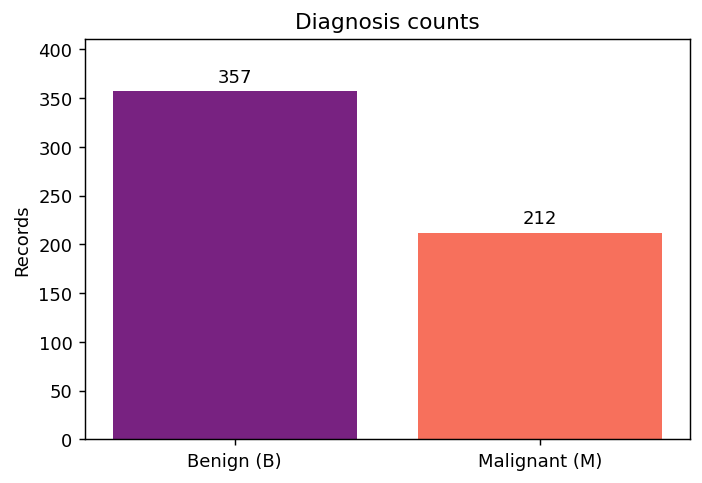

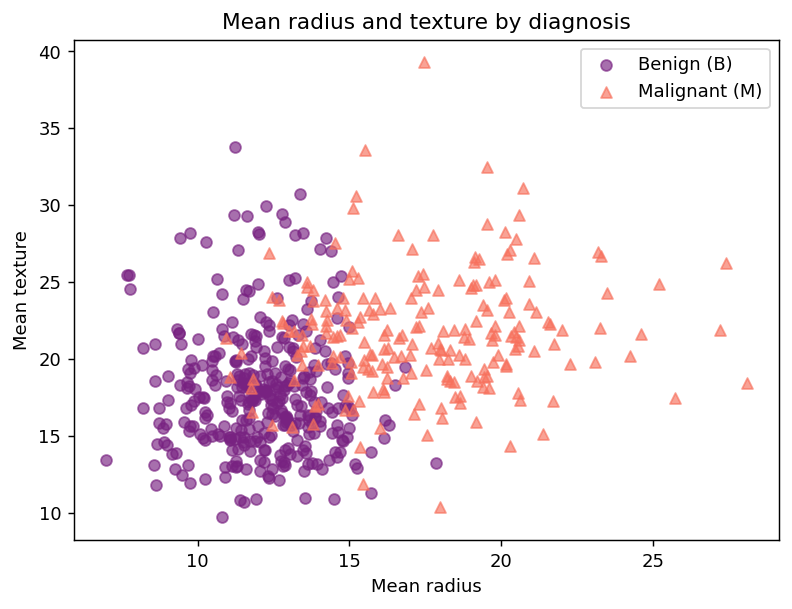

In [2]:
# Step 3. Count each diagnosis and draw a count plot with the magma palette.
counts = data["diagnosis"].value_counts().reindex(["B", "M"])
names = ["Benign (B)", "Malignant (M)"]
print(counts.rename(index=dict(zip(counts.index, names))).to_string())
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(names, counts, color=plt.get_cmap("magma")([0.35, 0.70]))
ax.bar_label(bars, padding=3)
ax.set(title="Diagnosis counts", ylabel="Records", ylim=(0, counts.max() * 1.15))
plt.show()

# Two measurements illustrate separation and overlap between the classes.
fig, ax = plt.subplots(figsize=(7, 5))
for label, name, marker, color in zip(
    ["B", "M"], names, ["o", "^"], plt.get_cmap("magma")([0.35, 0.70])
):
    group = data.loc[data["diagnosis"].eq(label)]
    ax.scatter(group["radius_mean"], group["texture_mean"], marker=marker,
               color=color, alpha=0.65, label=name)
ax.set(title="Mean radius and texture by diagnosis",
       xlabel="Mean radius", ylabel="Mean texture")
ax.legend()
plt.show()

In [3]:
# Step 4. Encode the diagnosis and hold out 20% of the rows. Stratification
# keeps the benign-to-malignant ratio similar in the two subsets.
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split

X = data.drop(columns="diagnosis")
y = data["diagnosis"].map({"B": 0, "M": 1})
assert y.notna().all()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print(f"Training: {len(y_train)} | Test: {len(y_test)}")

Training: 455 | Test: 114


In [4]:
# Step 5. Define the four classifiers and their preprocessing pipelines.
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Scaling puts features on comparable units for distance-based KNN, the
# RBF kernel, and regularized logistic regression. Trees split on feature
# order and can work with the original scale.
models = {
    "Logistic regression": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                         LogisticRegression(max_iter=2000)),
    "K-nearest neighbors": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                         KNeighborsClassifier(n_neighbors=5)),
    "Random forest": make_pipeline(SimpleImputer(strategy="median"),
                                   RandomForestClassifier(n_estimators=200, random_state=42)),
    "SVM (RBF)": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                               SVC(kernel="rbf", C=1.0)),
}

                     Mean CV accuracy  Test accuracy  Malignant recall
Model                                                                 
Logistic regression            97.36%         96.49%            92.86%
K-nearest neighbors            96.48%         95.61%            90.48%
Random forest                  96.26%         96.49%            90.48%
SVM (RBF)                      97.14%         97.37%            92.86%
Best by training CV: Logistic regression
Highest accuracy on this test split: SVM (RBF)


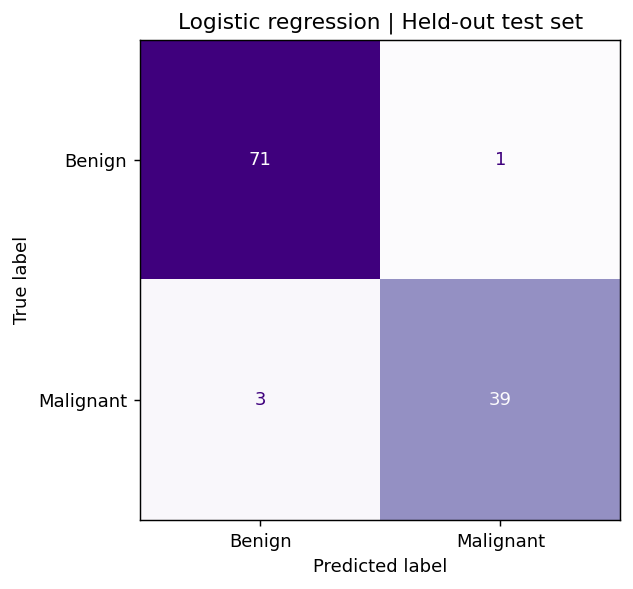

In [5]:
# Step 6. Compare training-only cross-validation accuracy, then fit each
# pipeline and evaluate it using the same held-out rows.
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, confusion_matrix, recall_score

results = []
predictions = {}
for name, model in models.items():
    validation = cross_val_score(model, X_train, y_train, cv=folds, scoring="accuracy")
    model.fit(X_train, y_train)
    predicted = model.predict(X_test)
    predictions[name] = predicted
    results.append({
        "Model": name,
        "Mean CV accuracy": validation.mean(),
        "Test accuracy": accuracy_score(y_test, predicted),
        "Malignant recall": recall_score(y_test, predicted),
    })
scores = pd.DataFrame(results).set_index("Model")
selected = scores["Mean CV accuracy"].idxmax()
leaders = scores.index[scores["Test accuracy"].eq(scores["Test accuracy"].max())].tolist()
print(scores.to_string(float_format=lambda score: f"{score:.2%}"))
print("Best by training CV:", selected)
print("Highest accuracy on this test split:", ", ".join(leaders))

# Step 7. Examine the selected model's actual errors. Rows are the recorded
# diagnoses and columns are the predicted diagnoses.
selected_prediction = predictions[selected]
tn, fp, fn, tp = confusion_matrix(y_test, selected_prediction, labels=[0, 1]).ravel()
ConfusionMatrixDisplay.from_predictions(
    y_test, selected_prediction, labels=[0, 1], display_labels=["Benign", "Malignant"],
    cmap="Purples", colorbar=False
)
plt.title(f"{selected} | Held-out test set")
plt.show()

## Which model is best?

**Logistic regression** had the best mean training cross-validation accuracy (97.36%). Its held-out accuracy was **96.49%**. The highest observed test accuracy was **97.37%**, achieved by SVM (RBF). Cross-validation gives the model-selection result, and the held-out scores show how each model performed on this particular split.

The selected model missed **3** malignant case(s) and flagged **1** benign case(s) as malignant. Accuracy counts both classes together, while malignant recall shows the fraction of actual malignant cases detected.